# NAO: observed EOF base and daily index of the hindcasts

## Purpose

Build the observed NAO pattern, verify it, project daily sea-level pressure of every experiment and of ERA5 onto it, and score the first weeks after the initial date.

## Inputs

NOAA-20C monthly sea-level pressure, 1836-2015 (E3SM Diags time series under `OBSERVATION_ROOT`) for the EOF base. Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Daily-mean PSL (00Z-00Z means of `ts/6hourly/1yr`). Reference: ERA5 daily PSL (`OBSERVATION_ROOT/ERA5/1x1/6hourly`, averaged to days).

## Method

EOF base: EOF1 of NDJFM monthly SLP anomalies (`BASE_START`-`BASE_END` monthly climatology) over 20-80N, 90W-40E, sqrt(cos lat) weighted, unit norm, positive near the Azores. PC1 is the projection of the anomalies on the EOF, the same operation as the daily index. Check: re-projection of the source data (correlation with the saved PC1 must be > 0.999).

Daily index: anomalies from the base monthly climatology, projected on EOF1 and standardized with the base NDJFM PC1 mean and std. Lead windows of `WINDOW_DAYS` from `INIT_DATE` (day 1 = init + 1): window means, and the correlation across days within each window with ERA5 (single initialization). A rebuilt EOF base recomputes every daily index.

## Outputs

`data/hind_atm_eval/nao/nao_eof_base_NOAA20C_<base>_NDJFM_20-80N_90W-40E.nc`, `nao_daily_<SOURCE>_<period>.nc`, `nao_window_means.csv`, `nao_window_corr.csv`; figures in `figure/hind_atm_eval/nao/`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_eval"

# Experiments: run key (file names, tables) -> figure label. Labels follow fcst_atm_eval: the experiment
# whose initial state the run starts from (CTRL10: piControl, CAPT10: ERA5, DART40: DART), written
# "<atm>A-<lnd>L" when atmosphere and land come from different ones. EXPERIMENTS_FULL (backup) is the full
# atm x lnd factorial, needed for the initial-state attribution (factorial effects and noise floors).
EXPERIMENTS_FULL = {
    "CTRL": "CTRL10-S0",           # piControl atm + piControl lnd
    "DARTOP": "DART40-S0",         # DART atm + DART lnd
    "ERA5OP": "CAPT10-S0",         # ERA5 atm + ERA5-forced lnd
    "ERA5DL": "CAPTA-DARTL-S0",    # ERA5 atm + DART lnd
    "ERA5BL": "CAPTA-CTRLL-S0",    # ERA5 atm + piControl lnd
    "DARTBL": "DARTA-CTRLL-S0",    # DART atm + piControl lnd
    "DARTBA": "CTRLA-DARTL-S0",    # piControl atm + DART lnd
    "DARTAE": "DARTA-CAPTL-S0",    # DART atm + ERA5-forced lnd
}
EXPERIMENTS_FCST = {k: EXPERIMENTS_FULL[k] for k in ("CTRL", "ERA5OP", "DARTOP")}
EXPERIMENTS = EXPERIMENTS_FCST  # or EXPERIMENTS_FULL
BASE_START, BASE_END = "1985-01-01", "2014-12-31"  # EOF base climatology
START, END = "2012-01-01", "2013-12-31"
INIT_DATE = "2012-01-01"
WINDOW_DAYS = 14
MAX_LEAD_DAYS = 84
FORCE_COMPUTE = False
RECHECK = False  # also check a reused EOF base (re-reads the NOAA-20C record)
SHOW = True
FIGURE_DPI = 300
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask
from util.hind_factorial import relabel_figure

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'nao', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
FACTORIAL = set(EXPERIMENTS) == set(EXPERIMENTS_FULL)  # the atm x lnd attribution needs all 8 runs
SET_NAME = "full" if FACTORIAL else "fcst_aligned" if set(EXPERIMENTS) == set(EXPERIMENTS_FCST) else "subset"
table_dir = data_dir
if not FACTORIAL:  # tables and figures of a subset kept apart from the full set; per-source files are shared
    table_dir, figure_dir = data_dir / SET_NAME, figure_dir / SET_NAME
    for d in (table_dir, figure_dir):
        d.mkdir(exist_ok=True)
print(f"[DATA] {data_dir}\n[TABLE] {table_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    relabel_figure(fig, EXPERIMENTS_FULL)  # run keys -> figure labels
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/nao
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/nao/fcst_aligned
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/nao/fcst_aligned


## 4. Read input

Monthly NOAA-20C SLP, opened only to build the EOF base (or with `RECHECK`, to check a saved one), and daily PSL. Saved diagnostics are reused: fields are opened lazily only for the sources whose output file is missing (all of them with `FORCE_COMPUTE`), and loaded in the Derive step. A missing or forced EOF base makes every daily index stale, so all sources are read then.

In [4]:
from configs.hind_experiment_config import check_experiments
from util.hind_model_data import open_model_daily
from util.hind_observation_data import open_reference_daily, reference_files

base_nc = data_dir / f"nao_eof_base_NOAA20C_{BASE_START[:4]}-{BASE_END[:4]}_NDJFM_20-80N_90W-40E.nc"
new_base = FORCE_COMPUTE or not base_nc.exists()
psl_monthly = None
if new_base or RECHECK:
    files, name = reference_files("NOAA20C", "psl", **ROOTS)
    psl_monthly = xr.open_mfdataset(files, chunks={"time": 240})[name]

check_experiments(EXPERIMENTS)
period = f"{START[:4]}-{END[:4]}"
SOURCES = ("ERA5", *EXPERIMENTS)
paths = {s: data_dir / f"nao_daily_{s}_{period}.nc" for s in SOURCES}


def saved(path):  # files written before slp_anom was added are recomputed
    if not path.exists():
        return False
    with xr.open_dataset(path) as ds:
        return "slp_anom" in ds


inputs = {s: (open_reference_daily("ERA5_DAILY", "PSL", start=START, end=END, **ROOTS) if s == "ERA5"
              else open_model_daily(s, "PSL", data_root=INPUT_DATA_ROOT, start=START, end=END))
          for s in SOURCES if new_base or not saved(paths[s])}
print(f"[READ] EOF base: {'NOAA-20C' if new_base else 'saved'}; daily: {', '.join(inputs) or 'nothing: every index is saved'}")

[READ] EOF base: saved; daily: ERA5, CTRL, ERA5OP, DARTOP


## 5. Derive

EOF1 and PC1 (when rebuilt), then the standardized daily NAO index per source. The expensive reductions of every source are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.nao_index import NaoConfig, NaoProjector, compute_nao_eof_base

cfg = NaoConfig(base_start=BASE_START, base_end=BASE_END, window_days=WINDOW_DAYS, max_lead_days=MAX_LEAD_DAYS)
base = compute_nao_eof_base(psl_monthly, cfg=cfg) if new_base else xr.load_dataset(base_nc)
projector = NaoProjector(base, cfg)
# optimize_graph=False: dask's optimizer drops tasks shared by nao_raw/nao_std/slp_anom (Missing dependency)
derived = compute_all({s: projector.project_daily(psl, s, compute=False) for s, psl in inputs.items()},
                      optimize_graph=False)

## 6. Save

Write the newly derived files, then reload every source from disk so the steps below use the same data as a rerun that reuses the files.

In [6]:
if new_base:
    base.to_netcdf(base_nc)
    print(f"[WRITE] {base_nc}")
for s, ds in derived.items():
    ds.to_netcdf(paths[s])
    print(f"[WRITE] {paths[s]}")
base = xr.load_dataset(base_nc)
daily = {s: xr.load_dataset(p) for s, p in paths.items()}

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/nao/nao_daily_ERA5_2012-2013.nc
[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/nao/nao_daily_CTRL_2012-2013.nc
[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/nao/nao_daily_ERA5OP_2012-2013.nc
[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/nao/nao_daily_DARTOP_2012-2013.nc


## 7. Check

EOF norm, explained variance, and re-projection of the source data; run when the base is built (or with `RECHECK`).

In [7]:
from util.nao_index import verify_nao_eof_base

check = verify_nao_eof_base(base, psl_monthly, cfg=cfg) if psl_monthly is not None else None
if check is None:
    print(f"[SKIP] saved EOF base not re-checked (set RECHECK = True)")
else:
    for key, value in check.items():
        if key != "reprojected_pc":
            print(f"{key:>28}: {value}")
    if check["flags"]:
        print("[WARN] failed checks:", check["flags"])

[SKIP] saved EOF base not re-checked (set RECHECK = True)


## 8. Scores

Lead-window means of every source and window correlations with ERA5.

In [8]:
from util.nao_index import nao_tables

means, acc, acc_table = nao_tables(daily, projector, INIT_DATE)
for name, table in (("nao_window_means", means), ("nao_slp_acc_windows", acc_table)):
    table.to_csv(table_dir / f"{name}.csv")
    print(f"[WRITE] {table_dir / f'{name}.csv'}")
display(means.round(2))
display(acc_table.round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/nao/fcst_aligned/nao_window_means.csv
[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/nao/fcst_aligned/nao_slp_acc_windows.csv


,ERA5,CTRL,ERA5OP,DARTOP
window,,,,
days 1-14,1.04,-1.28,2.09,1.42
days 15-28,0.06,-0.56,1.42,0.17
days 29-42,-0.22,0.01,1.02,0.53
days 43-56,0.96,0.65,-1.13,0.79
days 57-70,1.70,1.39,-0.80,0.87
days 71-84,0.83,1.70,-1.54,-1.10


,ACC d00-04,ACC d05-09,ACC d10-14,ACC d15-28,ACC_day0,efold_days
CTRL,-0.06,-0.06,0.36,-0.02,0.26,2.03
ERA5OP,0.90,0.35,0.21,0.14,0.99,6.62
DARTOP,0.91,0.49,0.27,-0.01,0.98,10.01


## 9. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/nao/fcst_aligned/nao_eof_base_NOAA20C_1985-2014_NDJFM_20-80N_90W-40E.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/nao/fcst_aligned/nao_daily_2012-01-01.png


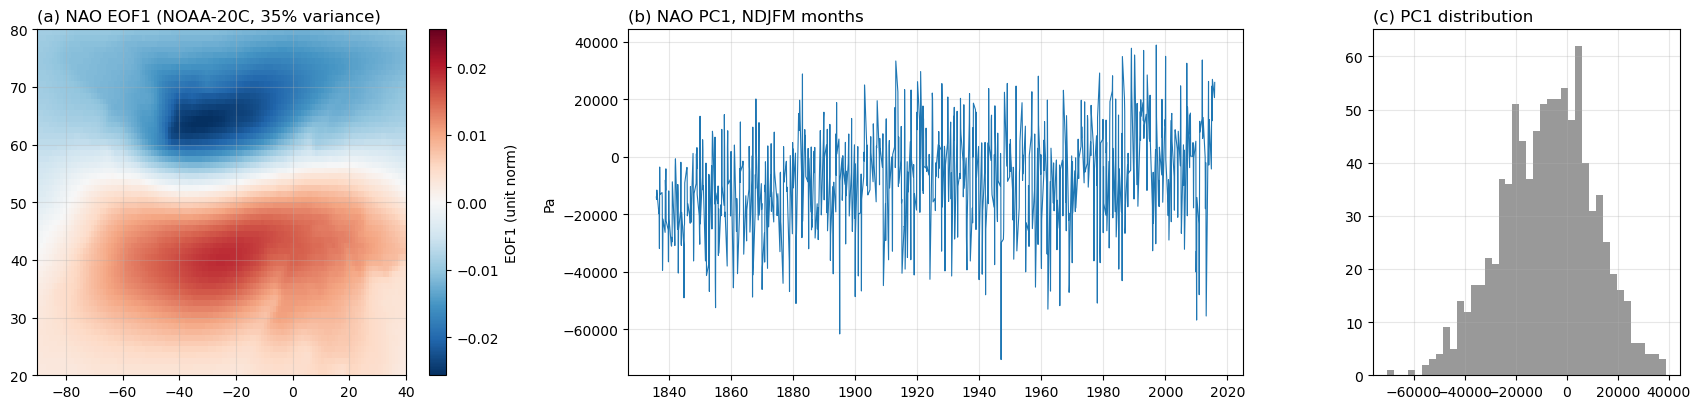

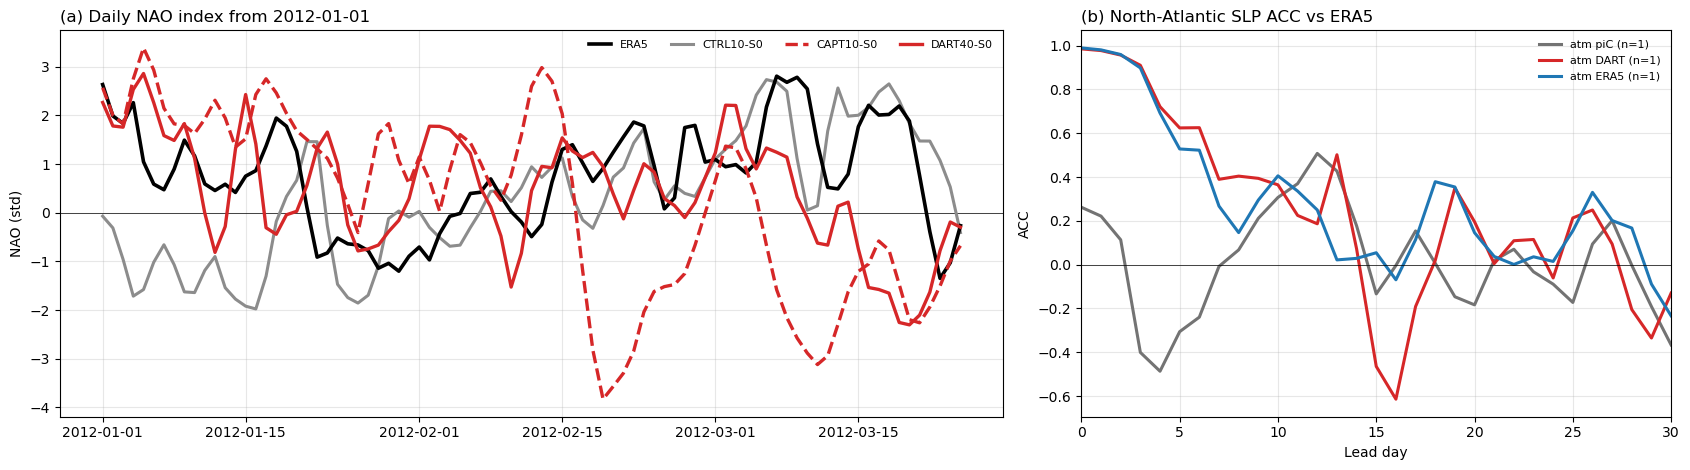

In [9]:
from util.nao_index import plot_nao_daily, plot_nao_eof_base

save(plot_nao_eof_base(base, check), f"{base_nc.stem}.png")
save(plot_nao_daily(daily, INIT_DATE, MAX_LEAD_DAYS, acc=acc), f"nao_daily_{INIT_DATE}.png")